In [42]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [21]:
#initial values dictionary
values=dict(L=0.01, V0=20, r=0.4, h=0.003, sigma=5.96*math.pow(10,7), R1=0.05, a=0.05, b=0.05, n=100, M=21.11, R=0.5)
#calculate coefficient values (more efficient this way)
def calc():
    c_1=-2*(math.pow(values['L'], 2)*math.pow(values['V0'],2)*math.pow(values['r'], 2)*values['h']*values['sigma'])
    c_2=-values['R1']/values['L']
    c_3=values['a']*values['b']*values['M']*math.pow(values['R'], 2)*math.pow(values['n'], 2)*values['R1']
    return c_1, c_2, c_3
c1, c2, c3 = calc()
#the derivative
def f(t, omega):
    return (c1*omega*math.pow((1-math.exp(c2*t)), 2))/c3
#differential equation solver (euler method)
def d(step, omega0, count):
    c0=-1
    a=np.array([]) #array for y values
    a_t=np.array([]) #array for torque values
    b=np.array([]) #array for x values
    yn=omega0
    c=0 #total time
    for i in range(count):
        b=np.append(b, c)
        a=np.append(a,yn)
        c+=step
        f_1=f(c, yn)
        yn1=yn+(step*f_1) #euler method
        yn=yn1
        a_t=np.append(a_t, f_1*values['M']*math.pow(values['R'], 2)/2)
        if yn<0.1*omega0 and c0<0: #check for the first time where omega<0.1*omega0 (t_0.1)
            c0=c
            print(c0)
            print(i)
    return a, b, c0, a_t

0.10500000000000198
1049
max torque: -377.01163797333186
0.08350000000000136
834
max torque: -459.502859701888
0.09230000000000162
922
max torque: -428.9672641038218
0.1092000000000021
1091
max torque: -385.4439014029518


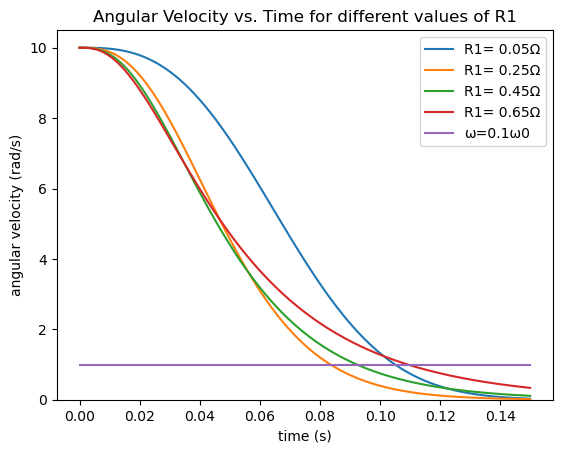

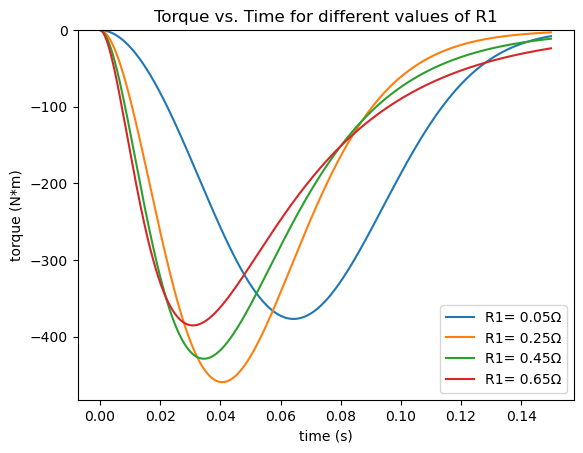

In [37]:
values=dict(L=0.01, V0=20, r=0.4, h=0.003, sigma=5.96*math.pow(10,7), R1=0.05, a=0.05, b=0.05, n=100, M=21.11, R=0.5)
#changing R1
values['R1']=0.05
c1, c2, c3=calc()
inc=0.2
final=0.65
fig, ax = plt.subplots()
fig2, ax2 = plt.subplots()
for i in range(int(final/inc)+1):
    y, x, t, y_t=d(0.0001, 10, 1500)
    t_max=y_t[0]
    n_count=0
    while t_max>=y_t[n_count]: #find max torque
        t_max=y_t[n_count]
        n_count+=1
    print('max torque: '+str(t_max))
    ax.plot(x, y, label='R1= '+str(round(values['R1'], 2))+"Ω") #plots multiple times on the same graph
    ax2.plot(x, y_t, label='R1= '+str(round(values['R1'], 2))+"Ω")
    values['R1']+=inc
    c1, c2, c3=calc()
#plot
ax.plot(np.array([0, 0.15]), np.array([1, 1]), label='ω=0.1ω0')
ax.set_title('Angular Velocity vs. Time for different values of R1')
ax.set_xlabel('time (s)')
ax.set_ylabel('angular velocity (rad/s)')
ax.set_ylim(0)
ax2.set_title('Torque vs. Time for different values of R1')
ax2.set_xlabel('time (s)')
ax2.set_ylabel('torque (N*m)')
ax2.set_ylim(top=0)
ax.legend()
ax2.legend()
plt.show()

fig.savefig('change_R1.png')
fig2.savefig('change_R1_t.png')
#explain why the graphs cross over

0.10500000000000198
1049
max torque: -37.70116379733321
0.10500000000000198
1049
max torque: -150.80465518933283
0.10500000000000198
1049
max torque: -263.9081465813324


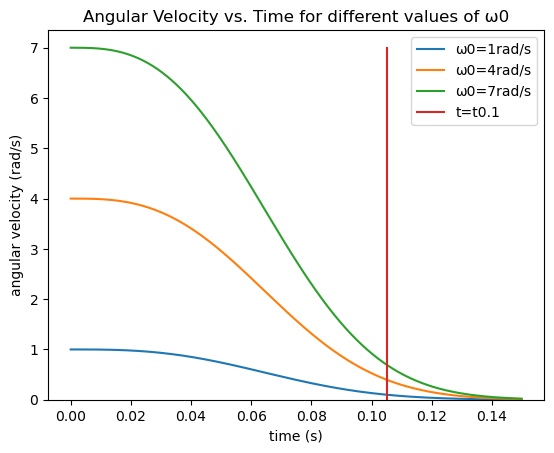

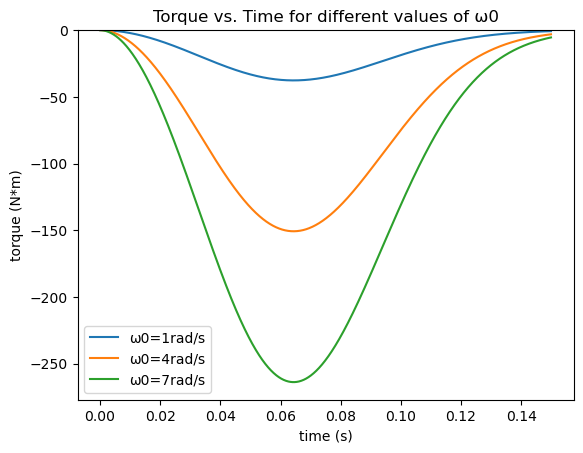

In [41]:
#changing omega0
values=dict(L=0.01, V0=20, r=0.4, h=0.003, sigma=5.96*math.pow(10,7), R1=0.05, a=0.05, b=0.05, n=100, M=21.11, R=0.5)
c1, c2, c3=calc()
inc=3
final=7
fig, ax = plt.subplots()
fig2, ax2 = plt.subplots()
for i in range(int(final/inc)+1):
    omega_value=1+i*inc
    y, x, t, y_t=d(0.0001, omega_value, 1500)
    t_max=y_t[0]
    n_count=0
    while t_max>=y_t[n_count]: #find max torque
        t_max=y_t[n_count]
        n_count+=1
    print('max torque: '+str(t_max))
    ax.plot(x, y, label="ω0="+str(omega_value)+"rad/s") #plots multiple times on the same graph
    ax2.plot(x, y_t, label="ω0="+str(omega_value)+"rad/s")
#plot
ax.plot(np.array([t, t]), np.array([0, 7]), label='t=t0.1')
ax.set_title('Angular Velocity vs. Time for different values of ω0')
ax.set_xlabel('time (s)')
ax.set_ylabel('angular velocity (rad/s)')
ax.set_ylim(0)
ax2.set_title('Torque vs. Time for different values of ω0')
ax2.set_xlabel('time (s)')
ax2.set_ylabel('torque (N*m)')
ax2.set_ylim(top=0)
ax.legend()
ax2.legend()
plt.show()

fig.savefig('change_omega.png')
fig2.savefig('change_omega_t.png')

0.10500000000000198
1049
max torque: -377.01163797333186


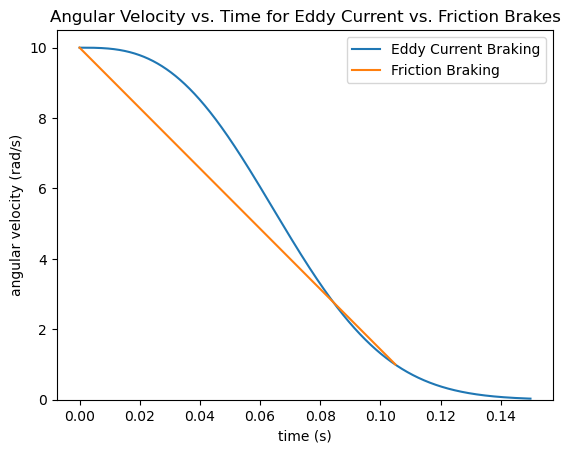

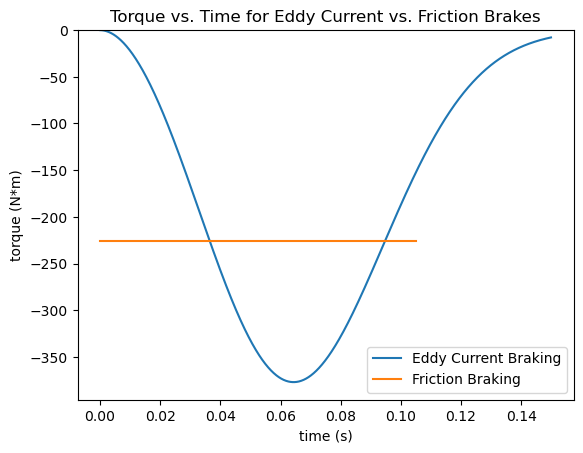

In [39]:
values=dict(L=0.01, V0=20, r=0.4, h=0.003, sigma=5.96*math.pow(10,7), R1=0.05, a=0.05, b=0.05, n=100, M=21.11, R=0.5)
c1, c2, c3=calc()

fig, ax = plt.subplots()
fig2, ax2 = plt.subplots()
y, x, t, y_t=d(0.0001, 10, 1500)
t_max=y_t[0]
n_count=0
while t_max>=y_t[n_count]: #find max torque
    t_max=y_t[n_count]
    n_count+=1
print('max torque: '+str(t_max))
ax.plot(x, y, label='Eddy Current Braking') #plots multiple times on the same graph
ax2.plot(x, y_t, label='Eddy Current Braking')
ax.plot(np.array([0, t]), np.array([y[0], y[1049]]), label='Friction Braking')
ax2.plot(np.array([0,t]), np.array([((y[1049]-y[0])/t)*0.5*values['M']*math.pow(values['R'],2), ((y[1049]-y[0])/t)*0.5*values['M']*math.pow(values['R'],2)]), label='Friction Braking')
ax.set_title('Angular Velocity vs. Time for Eddy Current vs. Friction Brakes')
ax.set_xlabel('time (s)')
ax.set_ylabel('angular velocity (rad/s)')
ax.set_ylim(0)
ax2.set_title('Torque vs. Time for Eddy Current vs. Friction Brakes')
ax2.set_xlabel('time (s)')
ax2.set_ylabel('torque (N*m)')
ax2.set_ylim(top=0)
ax.legend()
ax2.legend()
plt.show()

fig.savefig('comparison.png')
fig2.savefig('comparison_t.png')